In [2]:
ls

LRG_0_full_HPmapcut.ran.fits  LRG_full_HPmapcut_nz.txt
LRG_full_HPmapcut.dat.fits    LRG.ipynb


In [34]:
from astropy.io import fits

hdul = fits.open("LRG_full_HPmapcut.dat.fits")
data = hdul[1].data

print(data.names)

hdul_ran = fits.open("LRG_0_full_HPmapcut.ran.fits")
data_ran = hdul_ran[1].data

print(data_ran.names)


['TARGETID', 'MWS_TARGET', 'SUBPRIORITY', 'PRIORITY_INIT', 'TARGET_STATE', 'TIMESTAMP', 'LOCATION', 'TILEID', 'TILELOCID', 'LASTNIGHT', 'Z_not4clus', 'ZERR', 'ZWARN', 'CHI2', 'COEFF', 'NPIXELS', 'SPECTYPE', 'SUBTYPE', 'NCOEFF', 'DELTACHI2', 'FIBER', 'COADD_FIBERSTATUS', 'FIBERASSIGN_X', 'FIBERASSIGN_Y', 'PRIORITY', 'COADD_NUMEXP', 'COADD_EXPTIME', 'COADD_NUMNIGHT', 'MEAN_DELTA_X', 'RMS_DELTA_X', 'MEAN_DELTA_Y', 'RMS_DELTA_Y', 'MEAN_PSF_TO_FIBER_SPECFLUX', 'TSNR2_ELG_B', 'TSNR2_LYA_B', 'TSNR2_BGS_B', 'TSNR2_QSO_B', 'TSNR2_LRG_B', 'TSNR2_ELG_R', 'TSNR2_LYA_R', 'TSNR2_BGS_R', 'TSNR2_QSO_R', 'TSNR2_LRG_R', 'TSNR2_ELG_Z', 'TSNR2_LYA_Z', 'TSNR2_BGS_Z', 'TSNR2_QSO_Z', 'TSNR2_LRG_Z', 'TSNR2_ELG', 'TSNR2_LYA', 'TSNR2_BGS', 'TSNR2_QSO', 'TSNR2_LRG', 'ZWARN_MTL', 'Z_QN', 'Z_QN_CONF', 'IS_QSO_QN', 'PRIORITY_ASSIGNED', 'GOODPRI', 'GOODHARDLOC', 'LOCATION_ASSIGNED', 'TILELOCID_ASSIGNED', 'GOODTSNR', 'NTILE', 'TILES', 'TILELOCIDS', 'BRICKID', 'BRICKNAME', 'MORPHTYPE', 'RA', 'DEC', 'DCHISQ', 'EBV', 'F

In [35]:
import numpy as np

nz = np.loadtxt("LRG_full_HPmapcut_nz.txt")
print(nz[:10])


[[4.05000000e-01 4.00000000e-01 4.10000000e-01 5.28372738e-04
  2.65103415e+04 5.01735605e+07]
 [4.15000000e-01 4.10000000e-01 4.20000000e-01 5.37069113e-04
  2.79711738e+04 5.20811441e+07]
 [4.25000000e-01 4.20000000e-01 4.30000000e-01 5.22535327e-04
  2.82155367e+04 5.39973762e+07]
 [4.35000000e-01 4.30000000e-01 4.40000000e-01 5.27900614e-04
  2.95207849e+04 5.59211035e+07]
 [4.45000000e-01 4.40000000e-01 4.50000000e-01 5.39317531e-04
  3.12001318e+04 5.78511360e+07]
 [4.55000000e-01 4.50000000e-01 4.60000000e-01 5.36917987e-04
  3.21003652e+04 5.97863472e+07]
 [4.65000000e-01 4.60000000e-01 4.70000000e-01 5.14216393e-04
  3.17403134e+04 6.17255961e+07]
 [4.75000000e-01 4.70000000e-01 4.80000000e-01 5.16815837e-04
  3.29046204e+04 6.36679800e+07]
 [4.85000000e-01 4.80000000e-01 4.90000000e-01 5.17378605e-04
  3.39463902e+04 6.56122807e+07]
 [4.95000000e-01 4.90000000e-01 5.00000000e-01 5.18174271e-04
  3.50066668e+04 6.75577095e+07]]


In [36]:
z_mid = nz[:,0]
nz_pdf = nz[:,3]    # column 4

print("z_mid:", z_mid[:5])
print("n(z):", nz_pdf[:5])


z_mid: [0.405 0.415 0.425 0.435 0.445]
n(z): [0.00052837 0.00053707 0.00052254 0.0005279  0.00053932]


In [37]:
# STEP 6 (Part 1) -- Build CDF from n(z)
import numpy as np

nz_pdf = nz[:,3]
z_mid  = nz[:,0]

# convert to probability distribution that sums to 1
pdf = nz_pdf / np.sum(nz_pdf)

# cumulative distribution
cdf = np.cumsum(pdf)

print("cdf first 5:", cdf[:5])
print("cdf last:", cdf[-1])


cdf first 5: [0.01756931 0.03542779 0.05280299 0.0703566  0.08828985]
cdf last: 0.9999999999999997


In [38]:
N_ran = len(data_ran)
print("Number of random points:", N_ran)


Number of random points: 14350911


In [39]:
# STEP 6 (Part 3) — sample redshifts for the random catalog
import numpy as np

# generate N_ran uniform random numbers between 0 and 1
u = np.random.rand(N_ran)

# convert uniform numbers to redshift using inverse CDF sampling
z_random = np.interp(u, cdf, z_mid)

print("Random redshifts assigned:", z_random[:10])


Random redshifts assigned: [0.67807118 0.952646   0.41849218 0.78518202 0.88857098 0.47388037
 0.59735761 0.73901171 0.69325921 0.82436402]


In [40]:
print("Galaxy rows:", len(data))
print("Random rows:", len(data_ran))


Galaxy rows: 3461048
Random rows: 14350911


In [41]:
from astropy.cosmology import Planck15 as cosmo
import numpy as np

# Extract galaxy RA, DEC, Z
ra_gal  = data['RA']
dec_gal = data['DEC']
z_gal   = data['Z_not4clus']

# compute comoving distance in Mpc
chi_gal = cosmo.comoving_distance(z_gal).value

print(chi_gal[:10])


[2954.61184237    0.            0.         2140.26598868    0.
 2860.55279325    0.            0.         2863.73336253 2962.05776901]


/home/qarni/.local/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:2625: RuntimeWarning: invalid value encountered in _integral_comoving_distance_z1z2_scalar (vectorized)
  outputs = ufunc(*args, out=...)


In [42]:
from astropy.io import fits

hdul = fits.open("LRG_full_HPmapcut.dat.fits")
data = hdul[1].data

hdul_ran = fits.open("LRG_0_full_HPmapcut.ran.fits")
data_ran = hdul_ran[1].data

print("Galaxy rows:", len(data))
print("Random rows:", len(data_ran))


Galaxy rows: 3461048
Random rows: 14350911


In [43]:
# STEP 2 — Filter good galaxies
good = (data['Z_not4clus'] > 0) & (data['ZWARN'] == 0)

data_good = data[good]

print("Total galaxies:", len(data))
print("Good galaxies:", len(data_good))


Total galaxies: 3461048
Good galaxies: 2383819


In [44]:
from astropy.cosmology import Planck15 as cosmo
import numpy as np

# extract good galaxy sky+redshift
ra_gal  = data_good['RA']
dec_gal = data_good['DEC']
z_gal   = data_good['Z_not4clus']

# compute comoving distance (Mpc)
chi_gal = cosmo.comoving_distance(z_gal).value

print(chi_gal[:10])


[2954.61184237 2140.26598868 2860.55279325 2863.73336253 2962.05776901
 2395.01063143 3172.30023277 2070.52153256 1266.20174724 3867.41327511]


In [45]:
# STEP 4 — Convert Galaxy (RA, DEC, chi) to Cartesian coordinates

ra_rad  = np.deg2rad(ra_gal)
dec_rad = np.deg2rad(dec_gal)

x_gal = chi_gal * np.cos(dec_rad) * np.cos(ra_rad)
y_gal = chi_gal * np.cos(dec_rad) * np.sin(ra_rad)
z_gal = chi_gal * np.sin(dec_rad)

print(x_gal[:5], y_gal[:5], z_gal[:5])


[2589.89040682 1874.62045656 2504.98423966 2506.92115365 2593.09121095] [1029.68879594  748.32716337 1002.81893165 1005.56455863 1040.71859812] [-980.78529924 -711.71841531 -949.82652751 -951.39635245 -983.1424099 ]


In [46]:
from astropy.io import fits
import numpy as np
from astropy.cosmology import Planck15 as cosmo

# --- Load galaxy file ---
hdul = fits.open("LRG_full_HPmapcut.dat.fits")
data = hdul[1].data

# --- Load random file ---
hdul_ran = fits.open("LRG_0_full_HPmapcut.ran.fits")
data_ran = hdul_ran[1].data

# --- Load n(z) file ---
nz = np.loadtxt("LRG_full_HPmapcut_nz.txt")
z_mid  = nz[:,0]
nz_pdf = nz[:,3]             # probability density

# --- Build CDF again ---
pdf = nz_pdf / np.sum(nz_pdf)
cdf = np.cumsum(pdf)

print("Reloaded everything successfully.")


Reloaded everything successfully.


In [47]:
N_ran = len(data_ran)
u = np.random.rand(N_ran)
z_random = np.interp(u, cdf, z_mid)

print(z_random[:10])


[0.405      0.69139041 0.66410003 0.7233547  0.8226119  1.0260902
 0.52143379 0.87951196 0.57222774 0.76163733]


In [48]:
chi_ran = cosmo.comoving_distance(z_random).value
print(chi_ran[:10])


[1617.02515672 2552.96825762 2470.60726843 2647.71712324 2930.52516203
 3460.33000932 2017.13479507 3085.1897074  2183.09795519 2758.80673247]


In [49]:
# STEP 5.2 — Convert Randoms (RA, DEC, chi) → x, y, z

ra_ran  = data_ran['RA']
dec_ran = data_ran['DEC']

ra_ran_rad  = np.deg2rad(ra_ran)
dec_ran_rad = np.deg2rad(dec_ran)

x_ran = chi_ran * np.cos(dec_ran_rad) * np.cos(ra_ran_rad)
y_ran = chi_ran * np.cos(dec_ran_rad) * np.sin(ra_ran_rad)
z_ran = chi_ran * np.sin(dec_ran_rad)

print(x_ran[:5])
print(y_ran[:5])
print(z_ran[:5])


[1417.34286739 2237.56117232 2165.43700842 2316.28955185 2565.30904864]
[ 564.01455984  889.99217102  861.73599395  932.39887837 1027.80413084]
[-536.46726834 -847.86842141 -819.87432823 -880.81837418 -975.0824985 ]


In [20]:
x_all = np.concatenate([x_gal, x_ran])
y_all = np.concatenate([y_gal, y_ran])
z_all = np.concatenate([z_gal, z_ran])

print("x range:", x_all.min(), x_all.max())
print("y range:", y_all.min(), y_all.max())
print("z range:", z_all.min(), z_all.max())


x range: -8018.741527885642 7470.03777843577
y range: -7728.311254237003 7539.048135248903
z range: -2408.438823259918 6309.253794070634


In [50]:
x0 = np.median(x_gal)
y0 = np.median(y_gal)
z0 = np.median(z_gal)

print(x0, y0, z0)


-1160.5552309258214 17.972327290335464 268.442875180869


In [33]:
import pandas as pd
import os

# --------------------------------------------------------
# 1. Correct path to your LRG folder
# --------------------------------------------------------
LRG_FOLDER = "/home/qarni/galaxy_evolution_project/LRG"
os.makedirs(LRG_FOLDER, exist_ok=True)

# --------------------------------------------------------
# 2. Create GALAXY CSV
# --------------------------------------------------------
df_gal = pd.DataFrame({
    'RA': ra_gal,
    'DEC': dec_gal,
    'Z': z_gal,
    'x': x_gal,
    'y': y_gal,
    'z': z_gal
})

gal_path = os.path.join(LRG_FOLDER, "LRG_galaxies_xyz.csv")
df_gal.to_csv(gal_path, index=False)

print("Galaxy CSV saved at:", gal_path)

# --------------------------------------------------------
# 3. Create RANDOM CSV
# --------------------------------------------------------
df_ran = pd.DataFrame({
    'RA': ra_ran,
    'DEC': dec_ran,
    'Z': z_random,
    'x': x_ran,
    'y': y_ran,
    'z': z_ran
})

ran_path = os.path.join(LRG_FOLDER, "LRG_randoms_xyz.csv")
df_ran.to_csv(ran_path, index=False)

print("Random CSV saved at:", ran_path)


Galaxy CSV saved at: /home/qarni/galaxy_evolution_project/LRG/LRG_galaxies_xyz.csv
Random CSV saved at: /home/qarni/galaxy_evolution_project/LRG/LRG_randoms_xyz.csv


In [51]:
import numpy as np

# full box size
L = 16000.0
Ngrid = 128
dx = L / Ngrid  # ~125 Mpc

# center of the full survey
xc = 0.5 * (x_all.min() + x_all.max())
yc = 0.5 * (y_all.min() + y_all.max())
zc = 0.5 * (z_all.min() + z_all.max())

print("Center:", xc, yc, zc)

# define cubic boundaries
xmin = xc - L/2
xmax = xc + L/2
ymin = yc - L/2
ymax = yc + L/2
zmin = zc - L/2
zmax = zc + L/2

print("x:", xmin, xmax)
print("y:", ymin, ymax)
print("z:", zmin, zmax)


Center: -274.35187472493635 -94.63155949404972 1950.407485405358
x: -8274.351874724936 7725.648125275064
y: -8094.63155949405 7905.36844050595
z: -6049.592514594642 9950.407485405358


In [52]:
# shift coordinates to start at 0
xg_shift = x_gal - xmin
yg_shift = y_gal - ymin
zg_shift = z_gal - zmin

xr_shift = x_ran - xmin
yr_shift = y_ran - ymin
zr_shift = z_ran - zmin


In [53]:
ix_g = (xg_shift / dx).astype(int)
iy_g = (yg_shift / dx).astype(int)
iz_g = (zg_shift / dx).astype(int)

ix_r = (xr_shift / dx).astype(int)
iy_r = (yr_shift / dx).astype(int)
iz_r = (zr_shift / dx).astype(int)


In [54]:
density = np.zeros((Ngrid, Ngrid, Ngrid), dtype=np.float32)


In [55]:
def add_points(grid, ix, iy, iz):
    for i, j, k in zip(ix, iy, iz):
        if 0 <= i < Ngrid and 0 <= j < Ngrid and 0 <= k < Ngrid:
            grid[i, j, k] += 1.0


In [56]:
add_points(density, ix_g, iy_g, iz_g)


In [57]:
alpha = len(ix_g) / len(ix_r)
print("alpha =", alpha)


alpha = 0.1661092456081708


In [58]:
add_points(density, ix_r, iy_r, iz_r)
density = density - alpha * density


In [59]:
rho_mean = density.mean()
delta = (density - rho_mean) / rho_mean

print("delta field shape:", delta.shape)
print("delta min/max:", delta.min(), delta.max())


delta field shape: (128, 128, 128)
delta min/max: -1.0 484.73007


In [60]:
import h5py
import os

LRG_FOLDER = "/home/qarni/galaxy_evolution_project/LRG"

outfile = os.path.join(LRG_FOLDER, "density_field_lrg.h5")

with h5py.File(outfile, "w") as f:
    # save density field
    f.create_dataset("delta", data=delta, compression="gzip")
    
    # save metadata
    f.attrs["L"] = L             # box size (Mpc)
    f.attrs["Ngrid"] = Ngrid     # grid resolution
    f.attrs["dx"] = dx           # voxel size (Mpc)
    
    # box boundaries
    f.attrs["xmin"] = xmin
    f.attrs["xmax"] = xmax
    f.attrs["ymin"] = ymin
    f.attrs["ymax"] = ymax
    f.attrs["zmin"] = zmin
    f.attrs["zmax"] = zmax
    
    # center of box
    f.attrs["xc"] = xc
    f.attrs["yc"] = yc
    f.attrs["zc"] = zc
    
print(f"Saved density field to: {outfile}")


Saved density field to: /home/qarni/galaxy_evolution_project/LRG/density_field_lrg.h5


In [61]:
import h5py
import numpy as np

path = "/home/qarni/galaxy_evolution_project/LRG/density_field_lrg.h5"

with h5py.File(path, "r") as f:
    delta = f["delta"][...]
    L = f.attrs["L"]
    Ngrid = f.attrs["Ngrid"]
    dx = f.attrs["dx"]

print(delta.shape, L, Ngrid, dx)


(128, 128, 128) 16000.0 128 125.0


In [74]:
import numpy as np

step = 320.0   # half overlap

x_centers = np.arange(-8000, 7500, step)
y_centers = np.arange(-7800, 7500, step)
z_centers = np.arange(-2400, 6300, step)

print(len(x_centers), len(y_centers), len(z_centers))


49 48 28


In [83]:
import pandas as pd

ran = pd.read_csv("/home/qarni/galaxy_evolution_project/LRG/LRG_randoms_xyz.csv")
print("Total randoms:", len(ran))

import numpy as np

# Load galaxy coordinates from CSV
gal = pd.read_csv("/home/qarni/galaxy_evolution_project/LRG/LRG_galaxies_xyz.csv")

# Compute survey center (mean position)
x0 = np.mean(gal["x"])
y0 = np.mean(gal["y"])
z0 = np.mean(gal["z"])

print("New cube center candidate:")
print(x0, y0, z0)

import pandas as pd

ran = pd.read_csv("/home/qarni/galaxy_evolution_project/LRG/LRG_galaxies_xyz.csv")
print("Total galaxies:", len(gal))

Total randoms: 14350911
New cube center candidate:
-524.7826340742066 -41.68616374651914 500.1863884728165
Total galaxies: 2383819


In [87]:
import pandas as pd

gal = pd.read_csv("/home/qarni/galaxy_evolution_project/LRG/LRG_galaxies_xyz.csv")
ran = pd.read_csv("/home/qarni/galaxy_evolution_project/LRG/LRG_randoms_xyz.csv")

x_gal = gal["x"].values
y_gal = gal["y"].values
z_gal = gal["z"].values

x_ran = ran["x"].values
y_ran = ran["y"].values
z_ran = ran["z"].values

print("Loaded galaxies:", len(x_gal))
print("Loaded randoms:", len(x_ran))


Loaded galaxies: 2383819
Loaded randoms: 14350911


In [88]:
L = 640.0
half = L/2

xmin = x0 - half
xmax = x0 + half
ymin = y0 - half
ymax = y0 + half
zmin = z0 - half
zmax = z0 + half

print("x:", xmin, xmax)
print("y:", ymin, ymax)
print("z:", zmin, zmax)


x: -844.7826340742066 -204.7826340742066
y: -361.6861637465191 278.3138362534809
z: 180.18638847281647 820.1863884728165


In [89]:
gal_mask = (x_gal>xmin)&(x_gal<xmax)&(y_gal>ymin)&(y_gal<ymax)&(z_gal>zmin)&(z_gal<zmax)
ran_mask = (x_ran>xmin)&(x_ran<xmax)&(y_ran>ymin)&(y_ran<ymax)&(z_ran>zmin)&(z_ran<zmax)

xg = x_gal[gal_mask] - xmin
yg = y_gal[gal_mask] - ymin
zg = z_gal[gal_mask] - zmin

xr = x_ran[ran_mask] - xmin
yr = y_ran[ran_mask] - ymin
zr = z_ran[ran_mask] - zmin

print("Galaxies in cube:", len(xg))
print("Randoms in cube:", len(xr))


Galaxies in cube: 1227
Randoms in cube: 0


In [90]:
import numpy as np

# Arrays for galaxies and randoms
Xg, Yg, Zg = x_gal, y_gal, z_gal
Xr, Yr, Zr = x_ran, y_ran, z_ran

L = 640.0
half = L/2

# Try some cube centers: sample 500 random galaxy positions
idx = np.random.choice(len(Xg), 500, replace=False)
centers = np.vstack((Xg[idx], Yg[idx], Zg[idx])).T

best_gal = -1
best_center = None

for cx, cy, cz in centers:
    mask = (Xg>cx-half)&(Xg<cx+half)&(Yg>cy-half)&(Yg<cy+half)&(Zg>cz-half)&(Zg<cz+half)
    gal_count = mask.sum()
    
    if gal_count > best_gal:
        best_gal = gal_count
        best_center = (cx, cy, cz)

print("Best center found:", best_center)
print("Galaxies in that region:", best_gal)


Best center found: (np.float64(-2660.223583335546), np.float64(144.08543605417572), np.float64(7.225578654261795))
Galaxies in that region: 34237


In [93]:
x0 = -2660.223583335546
y0 =   144.08543605417572
z0 =     7.225578654261795
L = 640.0
half = L/2

xmin = x0 - half
xmax = x0 + half
ymin = y0 - half
ymax = y0 + half
zmin = z0 - half
zmax = z0 + half

print("x:", xmin, xmax)
print("y:", ymin, ymax)
print("z:", zmin, zmax)
gal_mask = (x_gal>xmin)&(x_gal<xmax)&(y_gal>ymin)&(y_gal<ymax)&(z_gal>zmin)&(z_gal<zmax)
ran_mask = (x_ran>xmin)&(x_ran<xmax)&(y_ran>ymin)&(y_ran<ymax)&(z_ran>zmin)&(z_ran<zmax)

xg = x_gal[gal_mask]
yg = y_gal[gal_mask]
zg = z_gal[gal_mask]

xr = x_ran[ran_mask]
yr = y_ran[ran_mask]
zr = z_ran[ran_mask]

print("Galaxies in cube:", len(xg))
print("Randoms in cube:", len(xr))
# Shift into cube coordinates (0 → 640)
xg = xg - xmin
yg = yg - ymin
zg = zg - zmin

xr = xr - xmin
yr = yr - ymin
zr = zr - zmin

print("Range galaxy x:", xg.min(), xg.max())
print("Range random x:", xr.min(), xr.max())


x: -2980.223583335546 -2340.223583335546
y: -175.91456394582428 464.0854360541757
z: -312.77442134573823 327.22557865426177
Galaxies in cube: 34237
Randoms in cube: 162050
Range galaxy x: 0.01162670485155104 639.9797054068094
Range random x: 0.010435482373850391 639.9948909735344


In [98]:
Ngrid = 128
dx = 640.0 / Ngrid   # = 5 Mpc

ix_g = (xg / dx).astype(int)
iy_g = (yg / dx).astype(int)
iz_g = (zg / dx).astype(int)

ix_r = (xr / dx).astype(int)
iy_r = (yr / dx).astype(int)
iz_r = (zr / dx).astype(int)

print("Galaxy grid index range:", ix_g.min(), ix_g.max())
print("Random grid index range:", ix_r.min(), ix_r.max())
import numpy as np
density = np.zeros((Ngrid, Ngrid, Ngrid), dtype=np.float32)
def add_points(ix, iy, iz):
    for i, j, k in zip(ix, iy, iz):
        if 0 <= i < Ngrid and 0 <= j < Ngrid and 0 <= k < Ngrid:
            density[i, j, k] += 1.0

add_points(ix_g, iy_g, iz_g)
alpha = len(ix_g) / len(ix_r)
add_points(ix_r, iy_r, iz_r)

density = density - alpha * density.mean()


Galaxy grid index range: 0 127
Random grid index range: 0 127


In [103]:
from scipy.ndimage import gaussian_filter

sigma = 1
delta_smoothed = gaussian_filter(density, sigma=sigma)

print("Smoothed delta min/max:", delta_smoothed.min(), delta_smoothed.max())
import numpy.fft as fft
import numpy as np

delta_k = fft.fftn(delta_smoothed)

kx = fft.fftfreq(Ngrid) * 2 * np.pi
ky = fft.fftfreq(Ngrid) * 2 * np.pi
kz = fft.fftfreq(Ngrid) * 2 * np.pi

kx, ky, kz = np.meshgrid(kx, ky, kz, indexing='ij')

k2 = kx**2 + ky**2 + kz**2
k2[0,0,0] = 1e-6   # avoid division by zero

phi_k = -delta_k / k2
Phi = fft.ifftn(phi_k).real

print("Potential field done.")
Txx_k = -(kx*kx) * phi_k
Tyy_k = -(ky*ky) * phi_k
Tzz_k = -(kz*kz) * phi_k

Txy_k = -(kx*ky) * phi_k
Txz_k = -(kx*kz) * phi_k
Tyz_k = -(ky*kz) * phi_k

Txx = fft.ifftn(Txx_k).real
Tyy = fft.ifftn(Tyy_k).real
Tzz = fft.ifftn(Tzz_k).real
Txy = fft.ifftn(Txy_k).real
Txz = fft.ifftn(Txz_k).real
Tyz = fft.ifftn(Tyz_k).real

print("Tidal tensor computed.")
env_map = np.zeros((Ngrid, Ngrid, Ngrid), dtype=np.int8)

for i in range(Ngrid):
    for j in range(Ngrid):
        for k in range(Ngrid):

            T = np.array([
                [Txx[i,j,k], Txy[i,j,k], Txz[i,j,k]],
                [Txy[i,j,k], Tyy[i,j,k], Tyz[i,j,k]],
                [Txz[i,j,k], Tyz[i,j,k], Tzz[i,j,k]]
            ])

            w = np.linalg.eigvals(T)
            w = np.sort(w)[::-1]   # λ1 ≥ λ2 ≥ λ3

            if (w[0] < 0 and w[1] < 0 and w[2] < 0):
                env_map[i,j,k] = 0   # VOID
            elif (w[0] > 0 and w[1] < 0 and w[2] < 0):
                env_map[i,j,k] = 1   # SHEET
            elif (w[0] > 0 and w[1] > 0 and w[2] < 0):
                env_map[i,j,k] = 2   # FILAMENT
            elif (w[0] > 0 and w[1] > 0 and w[2] > 0):
                env_map[i,j,k] = 3   # CLUSTER
import h5py

outname = "/home/qarni/galaxy_evolution_project/LRG/tweb_cube_single.h5"

with h5py.File(outname, "w") as f:
    f.create_dataset("env_map", data=env_map, compression="gzip")
    f.attrs["center_x"] = x0
    f.attrs["center_y"] = y0
    f.attrs["center_z"] = z0
    f.attrs["Ngrid"] = Ngrid
    f.attrs["L"] = 640.0
    f.attrs["dx"] = dx

print("Saved:", outname)


Smoothed delta min/max: -0.019774627 0.794362
Potential field done.
Tidal tensor computed.
Saved: /home/qarni/galaxy_evolution_project/LRG/tweb_cube_single.h5


In [109]:
import numpy as np
from astropy.io import fits

h = fits.open("LRG_SGC_clustering.dat.fits")
data = h[1].data

print("RA range:", data["RA"].min(), data["RA"].max())
print("DEC range:", data["DEC"].min(), data["DEC"].max())
print("Z range:", data["Z_not4clus"].min(), data["Z_not4clus"].max())

# ALSO: print approximate peaks
print("Median RA:", np.median(data["RA"]))
print("Median DEC:", np.median(data["DEC"]))
print("Median Z:", np.median(data["Z_not4clus"]))

RA range: 0.0003332064850813408 359.9996565868081
DEC range: -19.42312650558321 33.53153272667725


KeyError: "Key 'Z_not4clus' does not exist."

In [110]:
ls

LRG_0_full_HPmapcut.ran.fits   LRG_NGC_1_clustering.ran.fits
LRG_full_HPmapcut.dat.fits     LRG_NGC_clustering.dat.fits
LRG_full_HPmapcut_nz.txt       LRG_randoms_xyz.csv
LRG_galaxies_xyz.csv           LRG_SGC_clustering.dat.fits
LRG.ipynb                      tweb_cubes/
LRG_NGC_0_clustering.ran.fits  tweb_cube_single.h5


In [113]:
from astropy.io import fits
import numpy as np
import os

LRG_DIR = "/home/qarni/galaxy_evolution_project/LRG"

gal_path = os.path.join(LRG_DIR, "LRG_NGC_clustering.dat.fits")
gal_data = fits.open(gal_path)[1].data

# Extract RA, DEC, Z
ra_g  = gal_data["RA"]
dec_g = gal_data["DEC"]
z_g   = gal_data["Z"]

print("Galaxies loaded:", len(ra_g))
print("Z min/max:", np.nanmin(z_g), np.nanmax(z_g))
print("Z median:", np.nanmedian(z_g))


Galaxies loaded: 1476135
Z min/max: 0.4000003418878489 1.0999995514762086
Z median: 0.7546951617235444


In [112]:
from astropy.io import fits
h = fits.open("LRG_NGC_clustering.dat.fits")
data = h[1].data

print(data.dtype.names)


('TARGETID', 'Z', 'NTILE', 'RA', 'DEC', 'PHOTSYS', 'FRAC_TLOBS_TILES', 'WEIGHT_ZFAIL', 'WEIGHT_SYS', 'WEIGHT', 'WEIGHT_COMP', 'NX', 'WEIGHT_FKP')


In [4]:
from astropy.io import fits
import numpy as np
import os

LRG_DIR = "/home/qarni/galaxy_evolution_project/LRG"

# Load random chunk 0
ran0 = fits.open(os.path.join(LRG_DIR, "LRG_NGC_0_clustering.ran.fits"))[1].data
print("Random chunk 0:", len(ran0))

# Load random chunk 1
ran1 = fits.open(os.path.join(LRG_DIR, "LRG_NGC_1_clustering.ran.fits"))[1].data
print("Random chunk 1:", len(ran1))


# Merge
ran_data = np.hstack([ran0, ran1])
print("Total randoms loaded:", len(ran_data))
ra_r  = ran_data["RA"]
dec_r = ran_data["DEC"]
z_r   = ran_data["Z"]

print("Random Z min/max:", np.min(z_r), np.max(z_r))


Random chunk 0: 9389588
Random chunk 1: 9384611
Total randoms loaded: 18774199
Random Z min/max: 0.4000003418878489 1.0999995514762086


In [7]:
from astropy.io import fits
import numpy as np
import os

LRG_DIR = "/home/qarni/galaxy_evolution_project/LRG"

# Reload galaxies
gal_data = fits.open(os.path.join(LRG_DIR, "LRG_NGC_clustering.dat.fits"))[1].data

ra_g  = gal_data["RA"]
dec_g = gal_data["DEC"]
z_g   = gal_data["Z"]

print("Galaxies loaded:", len(ra_g))
print("Z range:", np.min(z_g), np.max(z_g))
ran0 = fits.open(os.path.join(LRG_DIR, "LRG_NGC_0_clustering.ran.fits"))[1].data
ran1 = fits.open(os.path.join(LRG_DIR, "LRG_NGC_1_clustering.ran.fits"))[1].data

ran_data = np.hstack([ran0, ran1])

ra_r  = ran_data["RA"]
dec_r = ran_data["DEC"]
z_r   = ran_data["Z"]

print("Randoms loaded:", len(ra_r))
print("Random Z range:", np.min(z_r), np.max(z_r))
ra_g, dec_g, z_g  
ra_r, dec_r, z_r
from astropy.cosmology import Planck15 as cosmo
import numpy as np

# Convert to radians
ra_rad_g  = np.radians(ra_g)
dec_rad_g = np.radians(dec_g)

chi_g = cosmo.comoving_distance(z_g).value

x_g = chi_g * np.cos(dec_rad_g) * np.cos(ra_rad_g)
y_g = chi_g * np.cos(dec_rad_g) * np.sin(ra_rad_g)
z_g = chi_g * np.sin(dec_rad_g)

print("Galaxy xyz sample:", x_g[:5], y_g[:5], z_g[:5])

# RANDOMS
ra_rad_r  = np.radians(ra_r)
dec_rad_r = np.radians(dec_r)

chi_r = cosmo.comoving_distance(z_r).value

x_r = chi_r * np.cos(dec_rad_r) * np.cos(ra_rad_r)
y_r = chi_r * np.cos(dec_rad_r) * np.sin(ra_rad_r)
z_r = chi_r * np.sin(dec_rad_r)

print("Random xyz sample:", x_r[:5], y_r[:5], z_r[:5])


Galaxies loaded: 1476135
Z range: 0.4000003418878489 1.0999995514762086
Randoms loaded: 18774199
Random Z range: 0.4000003418878489 1.0999995514762086
Galaxy xyz sample: [-1539.89133365 -2795.19751166 -2960.78591019 -2539.19283989
 -2835.45011407] [ 581.66632552 1104.06377146 1167.48283584  992.50713003 1106.70561949] [-294.86568915 -527.90918682 -554.33648935 -475.85504553 -532.20467181]
Random xyz sample: [-2703.40059075 -2312.98754822 -2486.2075617  -1937.14940195
 -2870.47261814] [1021.05786638  874.20390206  940.43555592  732.26582726 1089.23840771] [-516.18555982 -442.06695897 -475.54164562 -371.1710366  -549.95221731]


In [8]:
import numpy as np

# PARAMETERS
L = 640.0
half = L / 2

# Coarse grid step size (try cube centers every 200 Mpc)
step = 200  

best_count = 0
best_center = None

# Loop over possible cube centers
for xc in np.arange(-3500, -1500, step):
    for yc in np.arange(0, 1500, step):
        for zc in np.arange(-800, 200, step):

            # boundaries of the cube
            xmin, xmax = xc - half, xc + half
            ymin, ymax = yc - half, yc + half
            zmin, zmax = zc - half, zc + half

            # count galaxies inside cube
            inside = (x_g > xmin) & (x_g < xmax) & \
                     (y_g > ymin) & (y_g < ymax) & \
                     (z_g > zmin) & (z_g < zmax)

            count = np.sum(inside)

            if count > best_count:
                best_count = count
                best_center = (xc, yc, zc)

print("\nBest cube center found:", best_center)
print("Galaxies inside best cube:", best_count)



Best cube center found: (np.int64(-2700), np.int64(0), np.int64(0))
Galaxies inside best cube: 35309


In [9]:
L = 640.0
half = L/2

xc, yc, zc = best_center

xmin, xmax = xc - half, xc + half
ymin, ymax = yc - half, yc + half
zmin, zmax = zc - half, zc + half

# Select galaxies
gal_mask = (x_g > xmin) & (x_g < xmax) & \
           (y_g > ymin) & (y_g < ymax) & \
           (z_g > zmin) & (z_g < zmax)

xg = x_g[gal_mask]
yg = y_g[gal_mask]
zg = z_g[gal_mask]

print("Galaxies in cube:", len(xg))


# Select randoms
ran_mask = (x_r > xmin) & (x_r < xmax) & \
           (y_r > ymin) & (y_r < ymax) & \
           (z_r > zmin) & (z_r < zmax)

xr = x_r[ran_mask]
yr = y_r[ran_mask]
zr = z_r[ran_mask]

print("Randoms in cube:", len(xr))


Galaxies in cube: 35309
Randoms in cube: 354361


In [10]:
# Shift galaxy positions into cube coordinates
xg_shift = xg - xmin
yg_shift = yg - ymin
zg_shift = zg - zmin

# Shift random positions
xr_shift = xr - xmin
yr_shift = yr - ymin
zr_shift = zr - zmin

# Print example
print("Shifted galaxy sample:", xg_shift[:5], yg_shift[:5], zg_shift[:5])
print("Shifted random sample:", xr_shift[:5], yr_shift[:5], zr_shift[:5])


Shifted galaxy sample: [603.45006403 608.50127659 615.39917958 595.10172499 615.18450604] [581.87377962 566.1120305  558.3170797  493.54492737 491.43480512] [1.13433626 1.77879312 3.94944362 5.27429699 6.02378562]
Shifted random sample: [638.38882315 628.06115958 611.71627118 621.69992572 631.42184821] [628.64651891 617.58979971 622.66819344 618.35029454 601.00856144] [6.16623737 0.51318329 3.48592892 1.6061868  2.45350479]


In [15]:
Ngrid = 128
L = 640.0
dx = L / Ngrid   # = 5 Mpc

print("Grid resolution dx =", dx)
# Galaxy grid indices
ix_g = (xg_shift / dx).astype(int)
iy_g = (yg_shift / dx).astype(int)
iz_g = (zg_shift / dx).astype(int)

# Random indices
ix_r = (xr_shift / dx).astype(int)
iy_r = (yr_shift / dx).astype(int)
iz_r = (zr_shift / dx).astype(int)

print("Galaxy index range:", ix_g.min(), ix_g.max())
print("Random index range:", ix_r.min(), ix_r.max())
density = np.zeros((Ngrid, Ngrid, Ngrid), dtype=np.float32)

def add_points(ix, iy, iz):
    for i, j, k in zip(ix, iy, iz):
        if 0 <= i < Ngrid and 0 <= j < Ngrid and 0 <= k < Ngrid:
            density[i, j, k] += 1.0

# Add galaxies
add_points(ix_g, iy_g, iz_g)

# Compute alpha (normalization)
alpha = len(ix_g) / len(ix_r)
print("alpha =", alpha)

# Add randoms
add_points(ix_r, iy_r, iz_r)

# Complete density contrast
delta = density - alpha * density.mean()
print("delta min/max:", delta.min(), delta.max())
from scipy.ndimage import gaussian_filter

sigma = 1.0
delta_smooth = gaussian_filter(delta, sigma=sigma)

print("Smoothed delta min/max:", delta_smooth.min(), delta_smooth.max())
import numpy as np
import numpy.fft as fft

# Fourier transform of smoothed delta
delta_k = fft.fftn(delta_smooth)

# Prepare wave-numbers
kx = fft.fftfreq(Ngrid) * 2 * np.pi
ky = fft.fftfreq(Ngrid) * 2 * np.pi
kz = fft.fftfreq(Ngrid) * 2 * np.pi

kx, ky, kz = np.meshgrid(kx, ky, kz, indexing='ij')

k2 = kx**2 + ky**2 + kz**2
k2[0,0,0] = 1e-6   # avoid division by zero

# Solve Poisson equation for gravitational potential
phi_k = -delta_k / k2
Phi = fft.ifftn(phi_k).real

print("Phi min/max:", Phi.min(), Phi.max())
# Tidal tensor in Fourier space
Txx_k = -(kx * kx) * phi_k
Tyy_k = -(ky * ky) * phi_k
Tzz_k = -(kz * kz) * phi_k

Txy_k = -(kx * ky) * phi_k
Txz_k = -(kx * kz) * phi_k
Tyz_k = -(ky * kz) * phi_k

# Inverse FFT to real space
Txx = fft.ifftn(Txx_k).real
Tyy = fft.ifftn(Tyy_k).real
Tzz = fft.ifftn(Tzz_k).real

Txy = fft.ifftn(Txy_k).real
Txz = fft.ifftn(Txz_k).real
Tyz = fft.ifftn(Tyz_k).real

print("Txx min/max:", Txx.min(), Txx.max())
print("Tyy min/max:", Tyy.min(), Tyy.max())
print("Tzz min/max:", Tzz.min(), Tzz.max())
env_map = np.zeros((Ngrid, Ngrid, Ngrid), dtype=np.int8)

for i in range(Ngrid):
    for j in range(Ngrid):
        for k in range(Ngrid):

            # Build the 3x3 tidal tensor for voxel (i, j, k)
            T = np.array([
                [Txx[i,j,k], Txy[i,j,k], Txz[i,j,k]],
                [Txy[i,j,k], Tyy[i,j,k], Tyz[i,j,k]],
                [Txz[i,j,k], Tyz[i,j,k], Tzz[i,j,k]]
            ])

            # Eigenvalues (sorted λ1 ≥ λ2 ≥ λ3)
            w, _ = np.linalg.eig(T)
            w = np.sort(w)[::-1]

            # Classification based on signs (Pandey & Nandi)
            if w[0] < 0 and w[1] < 0 and w[2] < 0:
                env_map[i,j,k] = 0  # VOID
            elif w[0] > 0 and w[1] < 0 and w[2] < 0:
                env_map[i,j,k] = 1  # SHEET
            elif w[0] > 0 and w[1] > 0 and w[2] < 0:
                env_map[i,j,k] = 2  # FILAMENT
            elif w[0] > 0 and w[1] > 0 and w[2] > 0:
                env_map[i,j,k] = 3  # CLUSTER
import h5py
out = "/home/qarni/galaxy_evolution_project/LRG/tweb_cube_640.h5"

with h5py.File(out, "w") as f:
    f.create_dataset("env_map", data=env_map, compression="gzip")
    f.create_dataset("Txx", data=Txx)
    f.create_dataset("Tyy", data=Tyy)
    f.create_dataset("Tzz", data=Tzz)
    f.create_dataset("Txy", data=Txy)
    f.create_dataset("Txz", data=Txz)
    f.create_dataset("Tyz", data=Tyz)
    f.attrs["L"] = L
    f.attrs["Ngrid"] = Ngrid
    f.attrs["dx"] = dx
    f.attrs["center_x"] = xc
    f.attrs["center_y"] = yc
    f.attrs["center_z"] = zc

print("Saved cosmic web cube to:", out)
vals, counts = np.unique(env_map, return_counts=True)
labels = ["Void", "Sheet", "Filament", "Cluster"]

for v, c in zip(vals, counts):
    print(labels[v], ":", 100*c/np.sum(counts), "%")


Grid resolution dx = 5.0
Galaxy index range: 0 127
Random index range: 0 127
alpha = 0.09964132621817863
delta min/max: -0.018514268 5.981486
Smoothed delta min/max: -0.018514268 0.92506534
Phi min/max: -167302.76385868844 -167284.76261587703
Txx min/max: -0.21085043950076227 0.27363785498602183
Tyy min/max: -0.1908295834576417 0.31476315401905447
Tzz min/max: -0.2181650877196302 0.28821656916616006
Saved cosmic web cube to: /home/qarni/galaxy_evolution_project/LRG/tweb_cube_640.h5
Void : 8.369302749633789 %
Sheet : 43.056488037109375 %
Filament : 41.30401611328125 %
Cluster : 7.270193099975586 %


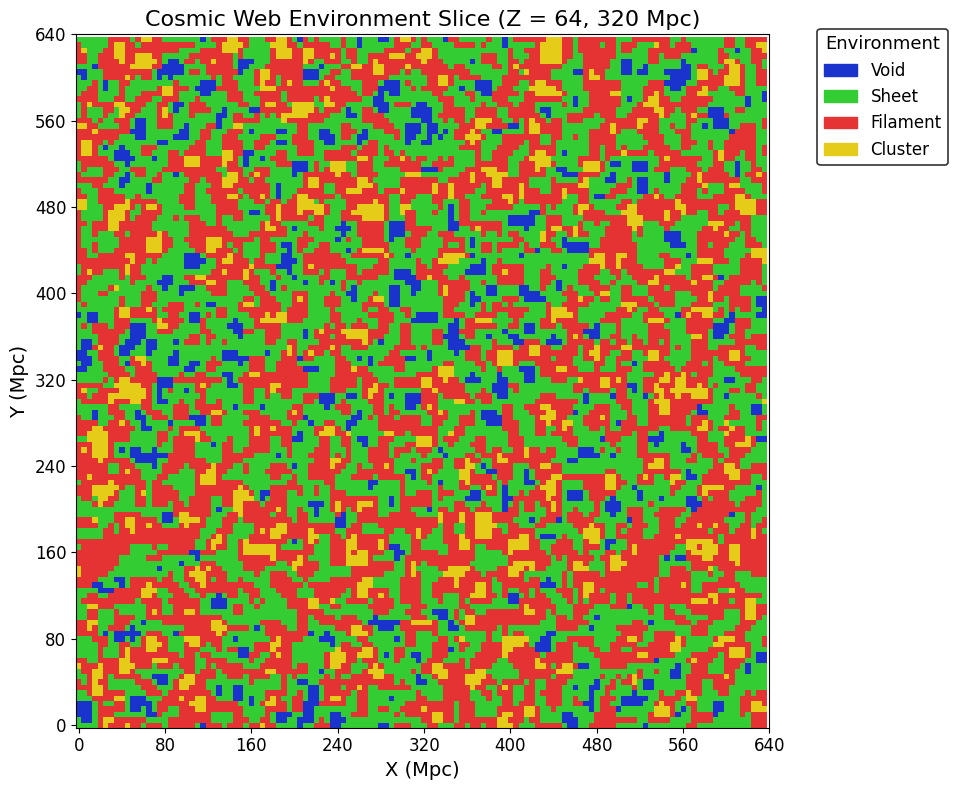

Saved figure to: /home/qarni/galaxy_evolution_project/LRG/tweb_slice_z64.png


In [17]:
import numpy as np
import matplotlib.pyplot as plt
import h5py
from matplotlib.patches import Patch

# ===================================================
# 1. Load T-Web cube
# ===================================================
web_file = "/home/qarni/galaxy_evolution_project/LRG/tweb_cube_640.h5"

with h5py.File(web_file, "r") as f:
    env_map = f["env_map"][:]

# Cube parameters
L = 640.0   # Mpc
Ngrid = env_map.shape[0]
dx = L / Ngrid

# ===================================================
# 2. Prepare slice
# ===================================================
mid = Ngrid // 2
slice_data = env_map[:, :, mid]

# ===================================================
# 3. Color definitions
# ===================================================
colors = np.array([
    [0.1, 0.2, 0.8],   # 0 = Void (blue)
    [0.2, 0.8, 0.2],   # 1 = Sheet (green)
    [0.9, 0.2, 0.2],   # 2 = Filament (red)
    [0.9, 0.8, 0.1],   # 3 = Cluster (yellow)
])

labels = ["Void", "Sheet", "Filament", "Cluster"]

rgb_image = colors[slice_data]

# ===================================================
# 4. Plot figure
# ===================================================
fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(rgb_image, origin='lower')

# Axis labels in Mpc
ax.set_xlabel("X (Mpc)", fontsize=14)
ax.set_ylabel("Y (Mpc)", fontsize=14)

# Set tick labels in Mpc
ticks = np.linspace(0, Ngrid, 9)   # 0, 16, 32, ..., 128
tick_labels = (ticks * dx).astype(int)

ax.set_xticks(ticks)
ax.set_xticklabels(tick_labels, fontsize=12)
ax.set_yticks(ticks)
ax.set_yticklabels(tick_labels, fontsize=12)

ax.set_title(f"Cosmic Web Environment Slice (Z = {mid}, {int(mid*dx)} Mpc)", fontsize=16)

# ===================================================
# 5. External legend
# ===================================================
legend_patches = [Patch(color=colors[i], label=labels[i]) for i in range(4)]

legend = ax.legend(
    handles=legend_patches,
    loc="upper right",
    bbox_to_anchor=(1.27, 1.02),
    frameon=True,
    title="Environment",
    title_fontsize=13,
    fontsize=12
)
legend.get_frame().set_edgecolor("black")
legend.get_frame().set_linewidth(1.2)

plt.tight_layout()

# ===================================================
# 6. Save figure
# ===================================================
save_path = "/home/qarni/galaxy_evolution_project/LRG/tweb_slice_z64.png"
plt.savefig(save_path, dpi=300, bbox_inches="tight")

plt.show()

print("Saved figure to:", save_path)


In [18]:
import h5py

file = "/home/qarni/galaxy_evolution_project/LRG/tweb_cube_640.h5"

with h5py.File(file, "r") as f:
    xc = f.attrs["center_x"]
    yc = f.attrs["center_y"]
    zc = f.attrs["center_z"]
    L  = f.attrs["L"]

print("Cube center:", xc, yc, zc)
print("Box size L:", L)


Cube center: -2700 0 0
Box size L: 640.0


In [19]:
half = L / 2

xmin = xc - half
xmax = xc + half

ymin = yc - half
ymax = yc + half

zmin = zc - half
zmax = zc + half


In [20]:
half = L / 2

xmin = xc - half
xmax = xc + half

ymin = yc - half
ymax = yc + half

zmin = zc - half
zmax = zc + half

print("x range:", xmin, xmax)
print("y range:", ymin, ymax)
print("z range:", zmin, zmax)


x range: -3020.0 -2380.0
y range: -320.0 320.0
z range: -320.0 320.0


Total galaxies loaded: 1476135
Galaxies in cube: 35309
Galaxies in slice: 1239


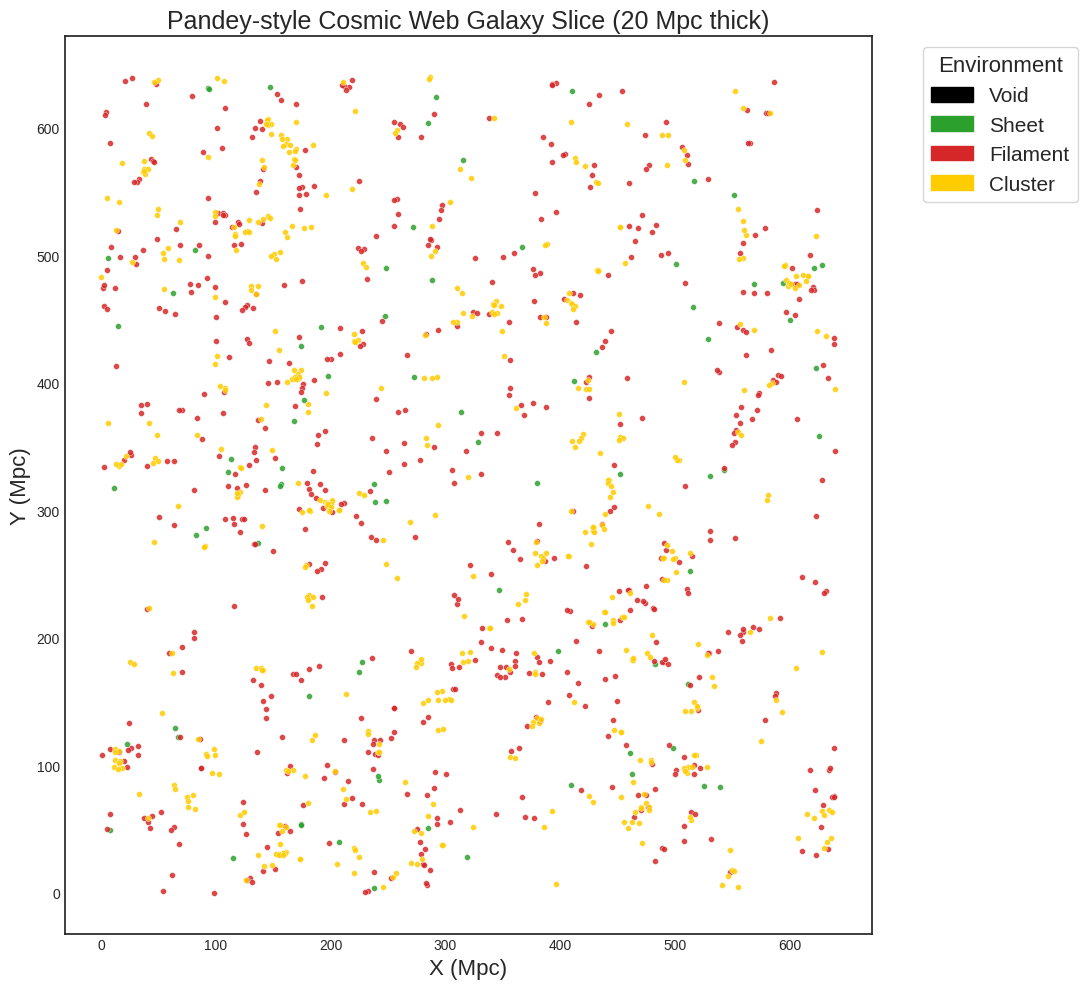

Saved: /home/qarni/galaxy_evolution_project/LRG/pandey_slice_beautiful.png


In [28]:
import numpy as np
import matplotlib.pyplot as plt
import h5py
from astropy.io import fits
from astropy.cosmology import Planck15 as cosmo
from matplotlib.patches import Patch

# =====================================================
# 1. LOAD GALAXIES
# =====================================================
gal_file = "/home/qarni/galaxy_evolution_project/LRG/LRG_NGC_clustering.dat.fits"
gal = fits.open(gal_file)[1].data

ra_g  = gal["RA"]
dec_g = gal["DEC"]
z_g   = gal["Z"]

print("Total galaxies loaded:", len(ra_g))

# Convert to xyz
ra_rad  = np.radians(ra_g)
dec_rad = np.radians(dec_g)
chi_g   = cosmo.comoving_distance(z_g).value

x_g = chi_g * np.cos(dec_rad) * np.cos(ra_rad)
y_g = chi_g * np.cos(dec_rad) * np.sin(ra_rad)
z_g = chi_g * np.sin(dec_rad)

# =====================================================
# 2. APPLY 640 Mpc CUBE CUT
# =====================================================
xc, yc, zc = -2700, 0, 0
L = 640.0
half = L / 2

xmin, xmax = xc - half, xc + half
ymin, ymax = yc - half, yc + half
zmin, zmax = zc - half, zc + half

mask_cube = (
    (x_g > xmin) & (x_g < xmax) &
    (y_g > ymin) & (y_g < ymax) &
    (z_g > zmin) & (z_g < zmax)
)

xg = x_g[mask_cube] - xmin
yg = y_g[mask_cube] - ymin
zg = z_g[mask_cube] - zmin

print("Galaxies in cube:", len(xg))

# =====================================================
# 3. LOAD T-Web environment map
# =====================================================
web_file = "/home/qarni/galaxy_evolution_project/LRG/tweb_cube_640.h5"
with h5py.File(web_file, "r") as f:
    env_map = f["env_map"][:]
    Ngrid = f.attrs["Ngrid"]

dx = L / Ngrid

ix = (xg / dx).astype(int)
iy = (yg / dx).astype(int)
iz = (zg / dx).astype(int)

env_labels = env_map[ix, iy, iz]

# =====================================================
# 4. SELECT 20 Mpc slice
# =====================================================
z_low  = 300
z_high = 320

slice_mask = (zg >= z_low) & (zg <= z_high)

xs = xg[slice_mask]
ys = yg[slice_mask]
env_s = env_labels[slice_mask]

print("Galaxies in slice:", len(xs))

# =====================================================
# 5. PLOT — BEAUTIFUL, PUBLISH-READY
# =====================================================

colors = {
    0: "black",     # Void
    1: "#2ca02c",   # Sheet
    2: "#d62728",   # Filament
    3: "#ffcc00"    # Cluster
}

labels = ["Void", "Sheet", "Filament", "Cluster"]

plt.figure(figsize=(11, 10))

for cls in [0,1,2,3]:
    m = (env_s == cls)
    plt.scatter(
        xs[m],
        ys[m],
        s=18,            # larger points
        color=colors[cls],
        edgecolor="white",
        linewidth=0.3,
        alpha=0.85       # better visibility
    )

plt.xlabel("X (Mpc)", fontsize=16)
plt.ylabel("Y (Mpc)", fontsize=16)
plt.title("Pandey-style Cosmic Web Galaxy Slice (20 Mpc thick)", fontsize=18)

# ---------- Legend outside ----------
legend_patches = [Patch(color=colors[i], label=labels[i]) for i in range(4)]

plt.legend(
    handles=legend_patches,
    loc="upper left",
    bbox_to_anchor=(1.05, 1),  # OUTSIDE
    frameon=True,
    fontsize=15,
    title="Environment",
    title_fontsize=16
)

plt.tight_layout()

savepath = "/home/qarni/galaxy_evolution_project/LRG/pandey_slice_beautiful.png"
plt.savefig(savepath, dpi=300, bbox_inches='tight')
plt.show()

print("Saved:", savepath)


Loaded env_map shape: (128, 128, 128)


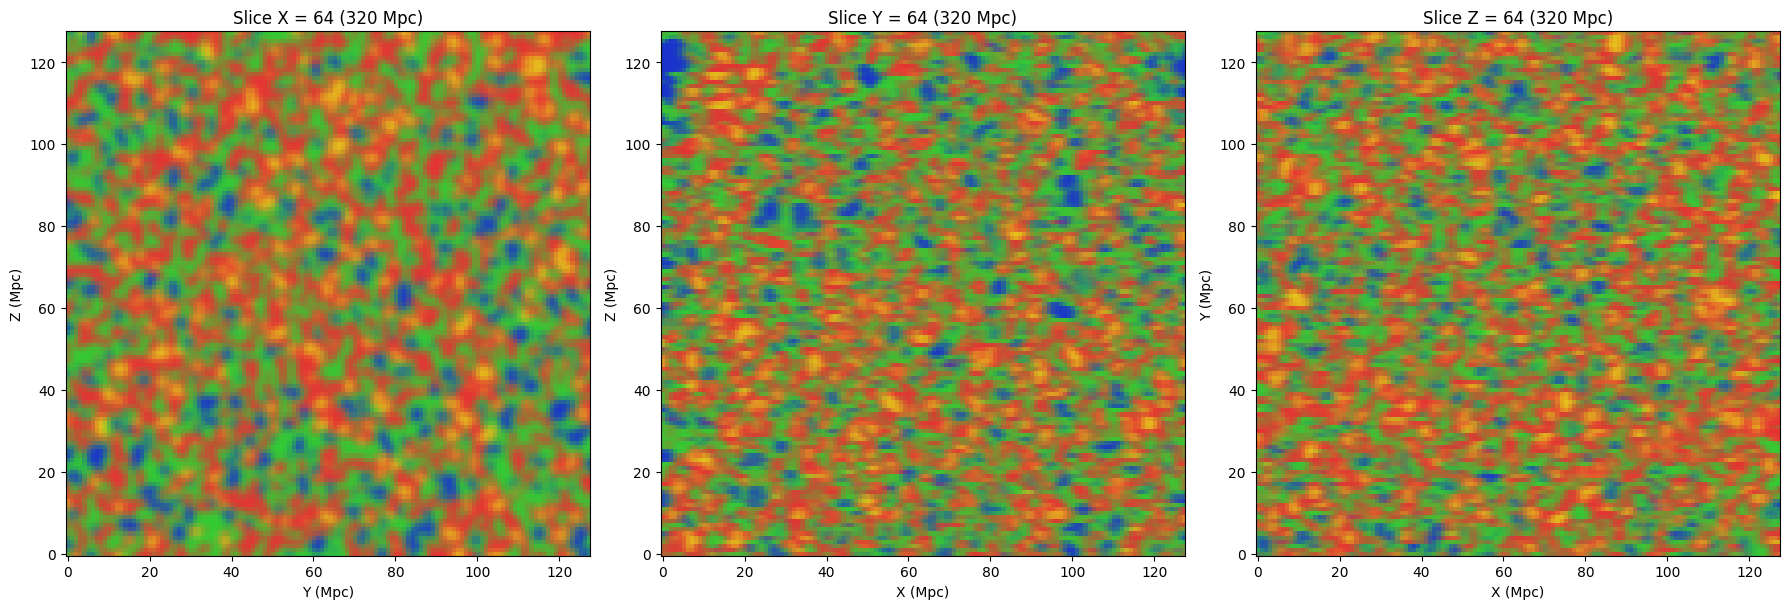

Saved improved voxel visualization to: /home/qarni/galaxy_evolution_project/LRG/tweb_voxel_3slices.png


In [23]:
import numpy as np
import matplotlib.pyplot as plt
import h5py
from scipy.ndimage import gaussian_filter

# ===============================================
# 1. Load your T-Web cube
# ===============================================
file = "/home/qarni/galaxy_evolution_project/LRG/tweb_cube_640.h5"

with h5py.File(file, "r") as f:
    env_map = f["env_map"][:]    # integer labels 0-3
    L = f.attrs["L"]
    Ngrid = f.attrs["Ngrid"]

dx = L / Ngrid
print("Loaded env_map shape:", env_map.shape)

# ===============================================
# 2. Convert env_map to RGB for smooth visualization
# ===============================================

# Colors for each environment
colors = np.array([
    [0.1, 0.2, 0.8],   # Void = blue
    [0.2, 0.8, 0.2],   # Sheet = green
    [0.9, 0.2, 0.2],   # Filament = red
    [0.9, 0.8, 0.1],   # Cluster = yellow
])

# Convert env_map into RGB cube
rgb_cube = colors[env_map]

# Apply Gaussian smoothing ONLY for visualization
rgb_smooth = gaussian_filter(rgb_cube, sigma=[0,1,1,0])

# ===============================================
# 3. Choose three slices: X, Y, Z mid-planes
# ===============================================
mid = Ngrid // 2

slice_X = rgb_smooth[mid, :, :]
slice_Y = rgb_smooth[:, mid, :]
slice_Z = rgb_smooth[:, :, mid]

# ===============================================
# 4. Plot the three slices
# ===============================================
fig, ax = plt.subplots(1, 3, figsize=(18, 6))

ax[0].imshow(slice_X, origin='lower')
ax[0].set_title(f"Slice X = {mid} ({int(mid*dx)} Mpc)")
ax[0].set_xlabel("Y (Mpc)")
ax[0].set_ylabel("Z (Mpc)")

ax[1].imshow(slice_Y, origin='lower')
ax[1].set_title(f"Slice Y = {mid} ({int(mid*dx)} Mpc)")
ax[1].set_xlabel("X (Mpc)")
ax[1].set_ylabel("Z (Mpc)")

ax[2].imshow(slice_Z, origin='lower')
ax[2].set_title(f"Slice Z = {mid} ({int(mid*dx)} Mpc)")
ax[2].set_xlabel("X (Mpc)")
ax[2].set_ylabel("Y (Mpc)")

plt.tight_layout()

# Save figure
savepath = "/home/qarni/galaxy_evolution_project/LRG/tweb_voxel_3slices.png"
plt.savefig(savepath, dpi=300, bbox_inches="tight")

plt.show()

print("Saved improved voxel visualization to:", savepath)
